# ` Intelligent E-Commerce Customer Analytics Platform `

### Purchase Prediction
    - **Objective** -  Predict whether a customer will place another order within the next 90 days.
    - **Target Variable** - Repeat Purchase

# Step 1 – Imports and project paths

In [8]:
from pathlib import Path
import json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, confusion_matrix, classification_report,
                             PrecisionRecallDisplay, RocCurveDisplay)

# Supports running the notebook from either the project root or notebooks/.
cwd = Path.cwd().resolve()
ROOT = cwd if (cwd / 'data').exists() else cwd.parent
RAW = ROOT / 'data' / 'raw'
ARTIFACTS = ROOT / 'artifacts'
ARTIFACTS.mkdir(parents=True, exist_ok=True)
print('Project root:', ROOT)
print('Raw data:', RAW)


Project root: C:\Users\RAaM\OneDrive\Desktop\E-Commerce Customer Analytics
Raw data: C:\Users\RAaM\OneDrive\Desktop\E-Commerce Customer Analytics\data\raw


# Step 2 – Read source tables at the correct grain

In [9]:
def find_raw(filename):
    hits = list(RAW.rglob(filename))
    if not hits:
        raise FileNotFoundError(f'Missing {filename} under {RAW}. Place original Olist CSV files in data/raw.')
    return hits[0]

orders = pd.read_csv(find_raw('olist_orders_dataset.csv'),
                     usecols=['order_id', 'customer_id', 'order_purchase_timestamp'])
customers = pd.read_csv(find_raw('olist_customers_dataset.csv'),
                        usecols=['customer_id', 'customer_unique_id'])
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'], errors='coerce')
orders = (orders.dropna(subset=['order_purchase_timestamp', 'order_id', 'customer_id'])
                .drop_duplicates('order_id')
                .merge(customers.drop_duplicates('customer_id'), on='customer_id', how='inner'))
orders = orders.dropna(subset=['customer_unique_id']).sort_values('order_purchase_timestamp')
print('Unique orders:', orders.order_id.nunique())
print('Unique customers:', orders.customer_unique_id.nunique())
print('Date range:', orders.order_purchase_timestamp.min(), 'to', orders.order_purchase_timestamp.max())


Unique orders: 99441
Unique customers: 96096
Date range: 2016-09-04 21:15:19 to 2018-10-17 17:30:18


# Step 3 – Construct historical customer snapshots

In [10]:
HORIZON_DAYS = 90
HORIZON = pd.Timedelta(days=HORIZON_DAYS)
last_date = orders.order_purchase_timestamp.max()
first_date = orders.order_purchase_timestamp.min()
# Monthly snapshots allow a useful sample while retaining strict time-based evaluation.
cutoffs = pd.date_range(first_date + pd.Timedelta(days=180),
                        last_date - HORIZON, freq='MS')
print('Eligible cutoff dates:', len(cutoffs), 'from', cutoffs.min(), 'to', cutoffs.max())
if len(cutoffs) < 6:
    raise ValueError('Not enough historical coverage for a meaningful temporal evaluation.')

def make_snapshot(cutoff):
    history = orders.loc[orders.order_purchase_timestamp < cutoff,
                         ['customer_unique_id', 'order_id', 'order_purchase_timestamp']]
    future = orders.loc[(orders.order_purchase_timestamp >= cutoff) &
                        (orders.order_purchase_timestamp < cutoff + HORIZON),
                        ['customer_unique_id', 'order_id']]
    agg = history.groupby('customer_unique_id').agg(
        total_orders=('order_id', 'nunique'),
        first_purchase=('order_purchase_timestamp', 'min'),
        last_purchase=('order_purchase_timestamp', 'max'))
    agg['recency_days'] = (cutoff - agg.last_purchase).dt.total_seconds() / 86400
    agg['tenure_days'] = (cutoff - agg.first_purchase).dt.total_seconds() / 86400
    for days in [30, 90, 180]:
        recent = history.loc[history.order_purchase_timestamp >= cutoff - pd.Timedelta(days=days)]
        agg[f'orders_last_{days}d'] = recent.groupby('customer_unique_id').order_id.nunique().reindex(agg.index, fill_value=0)
    agg['orders_per_month'] = agg.total_orders / np.maximum(agg.tenure_days / 30.44, 1)
    agg['repeat_purchase_90d'] = agg.index.isin(future.customer_unique_id.unique()).astype(int)
    agg['cutoff_date'] = cutoff
    return agg.drop(columns=['first_purchase', 'last_purchase']).reset_index()

snapshots = pd.concat([make_snapshot(c) for c in cutoffs], ignore_index=True)
FEATURES = ['total_orders', 'recency_days', 'tenure_days', 'orders_last_30d',
            'orders_last_90d', 'orders_last_180d', 'orders_per_month']
TARGET = 'repeat_purchase_90d'
print('Snapshot rows:', len(snapshots), 'positive rate:', round(snapshots[TARGET].mean(), 4))
display(snapshots.head())


Eligible cutoff dates: 16 from 2017-04-01 21:15:19 to 2018-07-01 21:15:19
Snapshot rows: 628918 positive rate: 0.0068


,customer_unique_id,total_orders,recency_days,tenure_days,orders_last_30d,orders_last_90d,orders_last_180d,orders_per_month,repeat_purchase_90d,cutoff_date
0,0000f46a3911fa3c0805444483337064,1,22.007130,22.007130,1,1,1,1.000000,0,2017-04-01 21:15:19
1,0005e1862207bf6ccc02e4228effd9a0,1,27.904942,27.904942,1,1,1,1.000000,0,2017-04-01 21:15:19
2,00115fc7123b5310cf6d3a3aa932699e,1,69.969954,69.969954,0,1,1,0.435044,0,2017-04-01 21:15:19
3,001f3c4211216384d5fe59b041ce1461,1,13.111609,13.111609,1,1,1,1.000000,0,2017-04-01 21:15:19
4,002043098f10ba39a4600b6c52fbfe3c,1,6.187037,6.187037,1,1,1,1.000000,0,2017-04-01 21:15:19


# Step - 4 Chronological train/test split

In [11]:
unique_cutoffs = sorted(snapshots.cutoff_date.unique())
test_cutoff = pd.Timestamp(unique_cutoffs[-1])
train_limit = test_cutoff - HORIZON
train = snapshots.loc[snapshots.cutoff_date <= train_limit].copy()
test = snapshots.loc[snapshots.cutoff_date == test_cutoff].copy()
assert train.cutoff_date.max() + HORIZON <= test_cutoff
print('Train through:', train.cutoff_date.max(), '| Test at:', test_cutoff)
print('Train rows:', len(train), 'Test rows:', len(test))
print('Train positives:', train[TARGET].sum(), 'Test positives:', test[TARGET].sum())
if train[TARGET].nunique() < 2 or test[TARGET].nunique() < 2:
    raise ValueError('Both classes are required in train and test; inspect cutoff dates.')
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]


Train through: 2018-04-01 21:15:19 | Test at: 2018-07-01 21:15:19
Train rows: 395701 Test rows: 83873
Train positives: 3072 Test positives: 295


# Step 4A - Class-imbalance and temporal coverage diagnostics

In [12]:
# The validation cutoff follows the original temporal design; no test labels are used for tuning.
validation_cutoff = train.cutoff_date.max()
fit_train_diagnostic = train.loc[train.cutoff_date <= validation_cutoff - HORIZON]
validation_diagnostic = train.loc[train.cutoff_date == validation_cutoff]

def class_summary(name, frame):
    count = len(frame)
    positives = int(frame[TARGET].sum())
    return {'Split': name, 'Rows': count, 'Positive': positives,
            'Negative': count - positives,
            'Positive rate': positives / count if count else np.nan,
            'First cutoff': str(frame.cutoff_date.min().date()) if count else 'N/A',
            'Last cutoff': str(frame.cutoff_date.max().date()) if count else 'N/A'}

split_diagnostics = pd.DataFrame([
    class_summary('Model fitting', fit_train_diagnostic),
    class_summary('Validation', validation_diagnostic),
    class_summary('Final train (after selection)', train),
    class_summary('Held-out test', test),
])
display(split_diagnostics)
print('Distinct test customers:', test.customer_unique_id.nunique())
print('Note: training snapshots repeat customers across historical cutoffs.')

,Split,Rows,Positive,Negative,Positive rate,First cutoff,Last cutoff
0,Model fitting,222085,1876,220209,0.008447,2017-04-01,2018-01-01
1,Validation,64639,443,64196,0.006853,2018-04-01,2018-04-01
2,Final train (after selection),395701,3072,392629,0.007763,2017-04-01,2018-04-01
3,Held-out test,83873,295,83578,0.003517,2018-07-01,2018-07-01


Distinct test customers: 83873
Note: training snapshots repeat customers across historical cutoffs.


# Step 5 - Train baseline and tree models

In [13]:
models = {
    'Logistic Regression': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=1500, class_weight='balanced', random_state=42))]),
    'Random Forest': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', RandomForestClassifier(n_estimators=200, min_samples_leaf=10,
                                        class_weight='balanced_subsample', random_state=42, n_jobs=-1))])
}
# Optional gradient-boosting models, if installed.
try:
    from lightgbm import LGBMClassifier
    models['LightGBM'] = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', LGBMClassifier(n_estimators=150, learning_rate=0.05,
                                 class_weight='balanced', random_state=42, verbosity=-1))])
except ImportError:
    print('LightGBM not installed; skipping.')
try:
    from xgboost import XGBClassifier
    ratio = max((y_train == 0).sum() / max((y_train == 1).sum(), 1), 1)
    models['XGBoost'] = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.05,
                                subsample=0.8, colsample_bytree=0.8,
                                scale_pos_weight=ratio, random_state=42,
                                eval_metric='logloss', n_jobs=4))])
except ImportError:
    print('XGBoost not installed; skipping.')

# Model selection uses only a temporal validation cutoff, not the final test cutoff.
val_cutoff = train.cutoff_date.max()
fit_train = train.loc[train.cutoff_date <= val_cutoff - HORIZON]
val = train.loc[train.cutoff_date == val_cutoff]
if fit_train[TARGET].nunique() < 2 or val[TARGET].nunique() < 2:
    raise ValueError('Insufficient temporal validation coverage.')
validation_rows = []
for name, pipeline in models.items():
    pipeline.fit(fit_train[FEATURES], fit_train[TARGET])
    p = pipeline.predict_proba(val[FEATURES])[:, 1]
    validation_rows.append({'Model': name, 'Validation PR-AUC': average_precision_score(val[TARGET], p),
                            'Validation ROC-AUC': roc_auc_score(val[TARGET], p)})
validation_results = pd.DataFrame(validation_rows).sort_values('Validation PR-AUC', ascending=False)
display(validation_results)
selected_name = validation_results.iloc[0]['Model']
print('Selected on validation PR-AUC:', selected_name)


,Model,Validation PR-AUC,Validation ROC-AUC
0,Logistic Regression,0.019176,0.587215
3,XGBoost,0.014167,0.554565
2,LightGBM,0.012569,0.558202
1,Random Forest,0.008104,0.534512


Selected on validation PR-AUC: Logistic Regression


# Step 5A - Select a decision threshold using validation data only

In [14]:
# Refit the selected candidate on fitting data only to obtain honest validation scores.
validation_model = models[selected_name]
validation_model.fit(fit_train[FEATURES], fit_train[TARGET])
val_prob = validation_model.predict_proba(val[FEATURES])[:, 1]

# Quantile grid handles weighted models whose probabilities may be poorly calibrated.
threshold_grid = np.unique(np.r_[0.5, np.quantile(val_prob, np.linspace(0.50, 0.995, 100))])
threshold_rows = []
for threshold in threshold_grid:
    val_pred = (val_prob >= threshold).astype(int)
    threshold_rows.append({
        'Threshold': float(threshold),
        'Precision': precision_score(val[TARGET], val_pred, zero_division=0),
        'Recall': recall_score(val[TARGET], val_pred, zero_division=0),
        'F1': f1_score(val[TARGET], val_pred, zero_division=0),
        'Flagged': int(val_pred.sum())
    })
threshold_results = pd.DataFrame(threshold_rows)
threshold_results = threshold_results.sort_values(['F1', 'Precision', 'Threshold'], ascending=[False, False, False])
selected_threshold = float(threshold_results.iloc[0]['Threshold'])
print('Validation-selected threshold:', round(selected_threshold, 6))
display(threshold_results.head(10))
print('Warning: selecting on a single validation cutoff can be unstable with rare positives.')

Validation-selected threshold: 0.852834


,Threshold,Precision,Recall,F1,Flagged
100,0.852834,0.070988,0.051919,0.059974,324
98,0.688746,0.042268,0.092551,0.058033,970
99,0.764049,0.044822,0.065463,0.053211,647
97,0.640344,0.035576,0.103837,0.052995,1293
96,0.562451,0.030941,0.112867,0.048567,1616
95,0.562273,0.026289,0.115124,0.042803,1940
94,0.562084,0.023862,0.121896,0.039911,2263
93,0.561928,0.022042,0.128668,0.037636,2586
92,0.561769,0.020282,0.133183,0.035203,2909
91,0.561544,0.018874,0.137698,0.033197,3232


# Step 5B - Validation Precision@K and Lift@K

In [15]:
TARGET_FRACTIONS = [0.01, 0.05, 0.10]

def ranking_metrics(y_true, probabilities, fractions=TARGET_FRACTIONS):
    y = np.asarray(y_true, dtype=int)
    scores = np.asarray(probabilities, dtype=float)
    if len(y) != len(scores) or not len(y):
        raise ValueError('Labels and scores must be nonempty and equal length.')
    baseline = float(y.mean())
    order = np.argsort(-scores, kind='stable')
    results = []
    for fraction in fractions:
        k = max(1, int(np.ceil(len(y) * fraction)))
        hits = int(y[order[:k]].sum())
        precision_k = hits / k
        results.append({'Top fraction': fraction, 'K': k,
                        'True repeat purchasers': hits, 'Precision@K': precision_k,
                        'Recall@K': hits / y.sum() if y.sum() else np.nan,
                        'Lift@K': precision_k / baseline if baseline else np.nan})
    return pd.DataFrame(results)

print('Validation positive rate / random PR-AUC baseline:', round(float(val[TARGET].mean()), 6))
display(ranking_metrics(val[TARGET], val_prob))

Validation positive rate / random PR-AUC baseline: 0.006853


,Top fraction,K,True repeat purchasers,Precision@K,Recall@K,Lift@K
0,0.01,647,29,0.044822,0.065463,6.540103
1,0.05,3232,61,0.018874,0.137698,2.753908
2,0.10,6464,86,0.013304,0.194131,1.941279


# Step 6 - Final test evaluation

Model                              Logistic Regression
Test ROC-AUC                                  0.605101
Test PR-AUC                                   0.011768
Test positive rate                            0.003517
Selected threshold (validation)               0.852834
Precision@0.5                                  0.00675
Recall@0.5                                    0.315254
F1@0.5                                        0.013217
Precision@selected                            0.030374
Recall@selected                               0.044068
F1@selected                                   0.035961
Flagged@selected                                   428
dtype: object
Confusion matrix at 0.5:
 [[69893 13685]
 [  202    93]]
Confusion matrix at validation-selected threshold:
 [[83163   415]
 [  282    13]]
Held-out test Precision@K / Lift@K:


,Top fraction,K,True repeat purchasers,Precision@K,Recall@K,Lift@K
0,0.01,839,21,0.025030,0.071186,7.116353
1,0.05,4194,47,0.011206,0.159322,3.186175
2,0.10,8388,69,0.008226,0.233898,2.338788


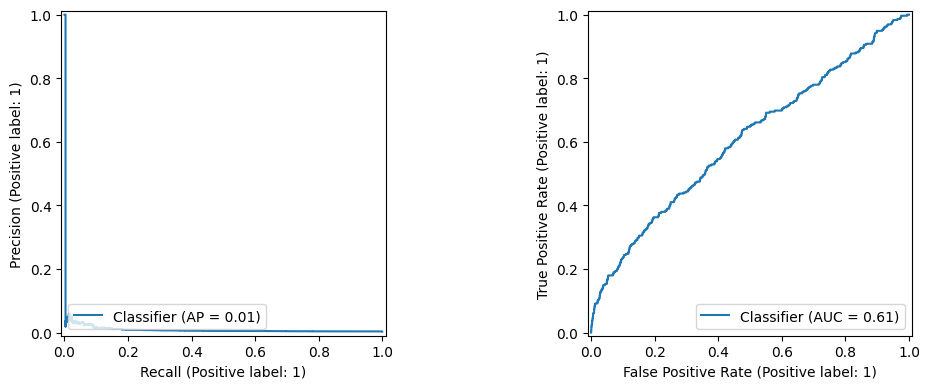

Test PR-AUC / prevalence lift: 3.35
CAUTION: PR-AUC, threshold and ranking metrics may be unstable with few positives.


In [16]:
# Final model fit uses all eligible training snapshots; test remains untouched.
best_model = models[selected_name]
best_model.fit(X_train, y_train)
prob = best_model.predict_proba(X_test)[:, 1]
pred_default = (prob >= 0.5).astype(int)
pred_selected = (prob >= selected_threshold).astype(int)

metrics = {
    'Model': selected_name,
    'Test ROC-AUC': roc_auc_score(y_test, prob),
    'Test PR-AUC': average_precision_score(y_test, prob),
    'Test positive rate': float(y_test.mean()),
    'Selected threshold (validation)': selected_threshold,
    'Precision@0.5': precision_score(y_test, pred_default, zero_division=0),
    'Recall@0.5': recall_score(y_test, pred_default, zero_division=0),
    'F1@0.5': f1_score(y_test, pred_default, zero_division=0),
    'Precision@selected': precision_score(y_test, pred_selected, zero_division=0),
    'Recall@selected': recall_score(y_test, pred_selected, zero_division=0),
    'F1@selected': f1_score(y_test, pred_selected, zero_division=0),
    'Flagged@selected': int(pred_selected.sum()),
}
print(pd.Series(metrics))
print('Confusion matrix at 0.5:\n', confusion_matrix(y_test, pred_default))
print('Confusion matrix at validation-selected threshold:\n', confusion_matrix(y_test, pred_selected))
print('Held-out test Precision@K / Lift@K:')
test_ranking_results = ranking_metrics(y_test, prob)
display(test_ranking_results)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
PrecisionRecallDisplay.from_predictions(y_test, prob, ax=axes[0])
RocCurveDisplay.from_predictions(y_test, prob, ax=axes[1])
plt.tight_layout()
plt.show()

print('Test PR-AUC / prevalence lift:', round(metrics['Test PR-AUC'] / metrics['Test positive rate'], 2))
print('CAUTION: PR-AUC, threshold and ranking metrics may be unstable with few positives.')

# Step 7 - . Save model and metadata

In [17]:
model_file = ARTIFACTS / 'repeat_purchase_90d_customer_v3.pkl'
metadata_file = ARTIFACTS / 'repeat_purchase_90d_customer_v3_metadata.json'
joblib.dump(best_model, model_file)
metadata = {'model': selected_name, 'target': TARGET, 'horizon_days': HORIZON_DAYS,
            'features': FEATURES, 'train_last_cutoff': str(train.cutoff_date.max().date()),
            'test_cutoff': str(test_cutoff.date()),
            'cutoff_convention': 'history < cutoff; target in [cutoff, cutoff + 90 days)',
            'selected_threshold': selected_threshold,
            'target_fractions': TARGET_FRACTIONS,
            'metrics': {k: float(v) for k, v in metrics.items() if isinstance(v, (float, np.floating, int, np.integer))},
            'test_ranking': test_ranking_results.to_dict(orient='records')}
metadata_file.write_text(json.dumps(metadata, indent=2), encoding='utf-8')
print('Saved:', model_file)
print('Saved:', metadata_file)
print('Reload test:', type(joblib.load(model_file)).__name__)


Saved: C:\Users\RAaM\OneDrive\Desktop\E-Commerce Customer Analytics\artifacts\repeat_purchase_90d_customer_v3.pkl
Saved: C:\Users\RAaM\OneDrive\Desktop\E-Commerce Customer Analytics\artifacts\repeat_purchase_90d_customer_v3_metadata.json
Reload test: Pipeline
